In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

<Axes: xlabel='temperature', ylabel='D_norm_T'>

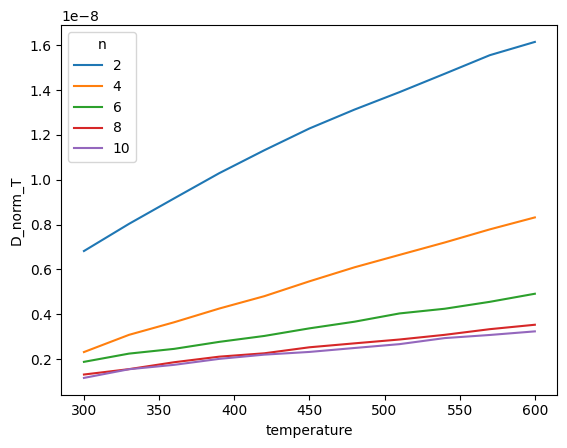

In [2]:
data = pd.read_pickle('../data/diffusion/diffusion_tst_datasetV2.pkl')
data['D_TST'] = data['D'] 
data['D_norm_T'] = data['D'] / data['temperature'] ** 0.5
sns.lineplot(x='temperature', y='D_norm_T', hue='n', data=data, palette='tab10')

<Axes: xlabel='n', ylabel='D_norm_m'>

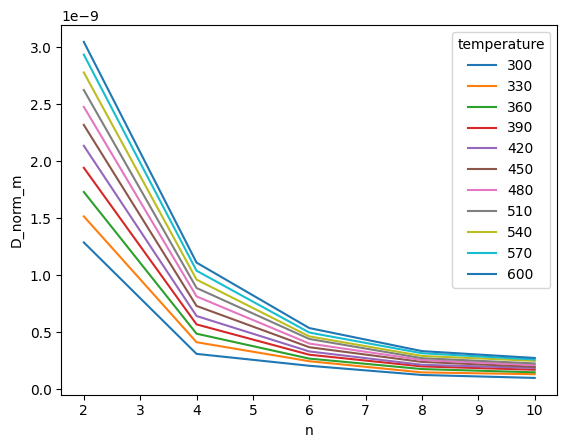

In [17]:
def mass_calc(n):
    """
    Calculate the mass of a molecule based on the number of atoms.
    """
    m = 1.008 * 2 * n + 12.01 * n
    return m

data['D_norm_m'] = data['D_norm_T'] / mass_calc(data['n']) ** 0.5
sns.lineplot(x='n', y='D_norm_m', hue='temperature', data=data.query('n <= 10'), palette='tab10')

It is not linear from sqrt(m) ... but as a placeholder it will be okay.

In [18]:
import joblib
from kinetic_model.constants.diffusion import DiffusionLinear

# 2) Fit & save
diff_model = DiffusionLinear()
diff_model.fit(data, D_col='D_TST')
joblib.dump(diff_model, '../data/processed/diffusion_model.pkl')

['../data/processed/diffusion_model.pkl']

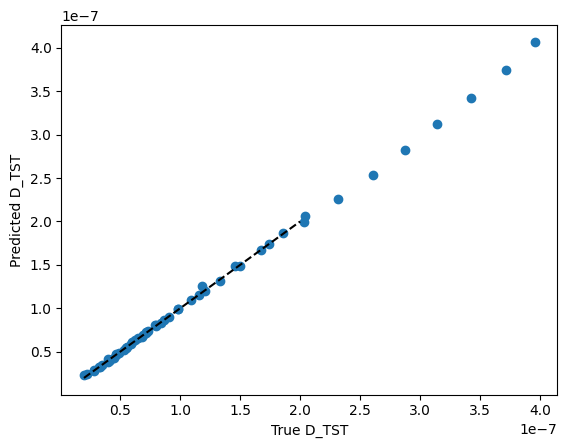

In [19]:
# 3) Later: load & predict
diff_loaded = joblib.load('../data/processed/diffusion_model.pkl')

y_pred = diff_loaded.predict(data[['temperature', 'n']])
y_true = data['D_TST'].to_numpy()
# 4) Plot
plt.scatter(y_true, y_pred)
plt.xlabel('True D_TST')
plt.ylabel('Predicted D_TST')
plt.plot([2e-8, 2e-7], [2e-8, 2e-7], 'k--')

In [20]:
from kinetic_model.constants.diffusion import DiffusionLinearExtrapPlaceHolder


diff_model_extrap = DiffusionLinearExtrapPlaceHolder()
diff_model_extrap.fit(data, D_col='D_TST')
joblib.dump(diff_model_extrap, '../data/processed/diffusion_extrap_place_holder_model.pkl')
model = joblib.load('../data/processed/diffusion_extrap_place_holder_model.pkl')
y_pred_extrap = model.predict(pd.DataFrame({'n': [2, 4, 6, 8, 10, 12], 'temperature': [300, 320, 301, 500, 100, 300]}))
y_pred_extrap

array([1.26225909e-07, 5.07443613e-08, 3.28163345e-08, 6.32792274e-08,
       9.26861942e-11, 3.35152383e-08])